# 06 — The operating boundary: where the study area came from, and what is inside it

**Almaty SuperSki terrain analytics — an independent open-data case study**
Dias Irishev · Geo & Weather Data Scientist, Almaty

Notebooks 01–03 report a 69 km² rectangle the author chose around the plateau.
Notebook 04 widens to the 404 km² cluster; notebook 05 narrows to a 42 km²
project window and reconstructs the stated 1,022 ha two ways.

**All four of those pick their study area by assertion.** This notebook replaces
that twice over — first with a rectangle derived from the operator's own
published general plan, then with a boundary drawn by hand over satellite
imagery — and reports what is actually inside it.

Everything here is computed by `src/pipeline_operating_area.py`. This notebook
calls that module rather than reimplementing it, so there is exactly one
implementation of every number and the PDF, the tables and this page can never
drift apart. Redraw `qgis/operating_area.geojson`, re-run, and every figure
below follows.

> **This boundary is not official.** Kazakh Tourism Development states a
> territory of 1,022 ha and has published no coordinates. Nothing here is
> commissioned by, affiliated with or endorsed by any operator or public body.

In [1]:
import os

os.environ["KZ_AREA"] = "superski"        # must be set before importing config

import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))

import footprint
import operating_area as OA
import pipeline_operating_area as PL
import ski_terrain as ST
import viz
from config import (AREA_LABEL, AREA_NOTE, HORIZON_N_AZIMUTH, INTERIM,
                    MIN_VALID_OBS, OUT_PNG, OUT_TAB, PROJECT_AREA_HA,
                    PROJECT_GREEN_BLUE_SHARE, PROJECT_GREEN_BLUE_SHARE_PRESS,
                    PROJECT_LIFTS, PROJECT_LIFTS_PRESS, PROJECT_PISTE_KM,
                    PROJECT_SNOWMAKING_SHARE, STUDY_AREAS, SUN_HOUR_STEP_MIN)
from grids import DEM_GRID

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

print(f"area        : {AREA_LABEL}")
print(f"grid        : {DEM_GRID.width} x {DEM_GRID.height} @ {DEM_GRID.res:.0f} m "
      f"= {DEM_GRID.area_km2:.0f} km2, {DEM_GRID.crs}")
print(f"horizon     : {HORIZON_N_AZIMUTH} azimuths ({360//HORIZON_N_AZIMUTH} deg)")
print(f"sun step    : {SUN_HOUR_STEP_MIN} min")

area        : Almaty SuperSki masterplan area
grid        : 389 x 358 @ 30 m = 125 km2, EPSG:32643
horizon     : 72 azimuths (5 deg)
sun step    : 10 min


## 1. Why the study area moved

The rectangle notebooks 01–03 use was chosen before the operator's general plan
was on hand. Measured against the features that plan names, it is in the wrong
place. The plan itself is a perspective panorama — no projection, no scale bar,
no graticule — so **nothing is traced from it**. What it carries is *named
features*, and those can be located independently in OpenStreetMap.

In [2]:
CONTROL_POINTS = {
    "MEDEU":                    (77.05757, 43.15944, "OSM place, suburb"),
    "KOKGAILAU PLATEAU 1951 m":  (77.00433, 43.14239, "project reference point"),
    "THREE BROTHERS ROCKS":     (77.01337, 43.12687, "OSM peak «Три брата», 2860 m"),
    "MOUNTAIN KUMBEL 3250 m":   (77.03130, 43.11934, "OSM peak «Qumbel», 3221 m"),
    "KUMBELTAU RANGE 3500 m":   (77.04056, 43.08490, "OSM peak «Qumbeltau», 3618 m"),
    "KIMASAR":                  (77.08281, 43.17116, "OSM saddle «Кімасар», 2080 m"),
    "SHYMBULAK":                (77.09312, 43.12275, "OSM landuse=winter_sports"),
}
cp = pd.DataFrame([{"sheet_label": k, "lon": v[0], "lat": v[1], "located_as": v[2]}
                   for k, v in CONTROL_POINTS.items()])
old = STUDY_AREAS["kok_zhailau"]["bbox"]
cp["inside_old_rectangle"] = [(old[0] <= r.lon <= old[2]) and (old[1] <= r.lat <= old[3])
                              for r in cp.itertuples()]
print(cp.to_string(index=False))
print(f"\ncontrol points the superseded 69 km2 rectangle misses: "
      f"{(~cp.inside_old_rectangle).sum()} of {len(cp)}")

             sheet_label      lon      lat                   located_as  inside_old_rectangle
                   MEDEU 77.05757 43.15944            OSM place, suburb                  True
KOKGAILAU PLATEAU 1951 m 77.00433 43.14239      project reference point                  True
    THREE BROTHERS ROCKS 77.01337 43.12687 OSM peak «Три брата», 2860 m                  True
  MOUNTAIN KUMBEL 3250 m 77.03130 43.11934    OSM peak «Qumbel», 3221 m                  True
  KUMBELTAU RANGE 3500 m 77.04056 43.08490 OSM peak «Qumbeltau», 3618 m                 False
                 KIMASAR 77.08281 43.17116 OSM saddle «Кімасар», 2080 m                 False
               SHYMBULAK 77.09312 43.12275    OSM landuse=winter_sports                 False

control points the superseded 69 km2 rectangle misses: 3 of 7


The old rectangle fails on three counts at once, and the failures point the same
way: it sampled the ground **below** the resort and stopped short of the ground
**above** it.

In [3]:
dem_old = np.load(INTERIM.parent / "terrain.npz")["dem"]      # kok_zhailau cache
dem_new = np.load(INTERIM / "terrain.npz")["dem"]
BANDS = {"below the base village (<1,900 m)": (0, 1900),
         "the plan's operating band (1,900–3,400 m)": (1900, 3400),
         "above the plan's top station (>3,400 m)": (3400, 1e9)}
rows = []
for label, d, res in (("superseded 69 km²", dem_old, 30.0), ("superski 125 km²", dem_new, 30.0)):
    ha = res ** 2 / 1e4
    row = {"rectangle": label, "total_ha": round(float(np.isfinite(d).sum() * ha))}
    for name, (lo, hi) in BANDS.items():
        row[name] = round(float(((d >= lo) & (d < hi)).sum() * ha))
    rows.append(row)
extent = pd.DataFrame(rows)
print(extent.to_string(index=False))
print("\nThe replacement more than doubles the terrain the plan actually uses,")
print("while the ground below the village grows by only ~160 ha.")

        rectangle  total_ha  below the base village (<1,900 m)  the plan's operating band (1,900–3,400 m)  above the plan's top station (>3,400 m)
superseded 69 km²      6912                               2598                                       4314                                        0
 superski 125 km²     12534                               2810                                       9187                                      537

The replacement more than doubles the terrain the plan actually uses,
while the ground below the village grows by only ~160 ha.


The `superski` rectangle is the envelope of those seven control points plus a
1.5 km working buffer. It is **derived, not given** — and it is still only a
compute grid, because a rectangle is not a site.

## 2. The boundary itself

The reporting boundary is a polygon digitised by hand over satellite imagery and
exported as KML. `operating_area.py` loads it, refuses anything that is not a
single valid polygon, rasterises it onto any grid, and carries one provenance
sentence into every caption so a reader never has to ask which boundary a number
came from.

In [4]:
poly, props = OA.load()
summary = OA.summary(poly, DEM_GRID, dem_new, np.load(INTERIM / "terrain.npz")["slope"])
print(f"provenance : {OA.provenance(props)}\n")
for k, v in summary.items():
    print(f"  {k:24s} {v}")
print(f"\nstated territory         {PROJECT_AREA_HA:,.0f} ha")
print(f"drawn boundary           {summary['raster_area_ha']:,.0f} ha "
      f"= {100 * summary['raster_area_ha'] / PROJECT_AREA_HA:.0f} % of it")

provenance : Boundary digitised by the author (Google Earth, hand-digitised over satellite imagery, exported as KML, 2026-11-19). Not an official boundary. Kazakh Tourism Development states a territory of 1,022 ha but has published no coordinates; this polygon is one informed reading of the operating area from imagery and the operator's general-plan sheet, and is larger than the stated territory.

  area_ha                  1776.3
  area_km2                 17.76
  perimeter_km             23.19
  n_vertices               24
  bounds_wgs84             (76.96202, 43.09839, 77.0408, 43.14586)
  pixels                   19728
  raster_area_ha           1775.5
  elev_min_m               1775.0
  elev_max_m               3291.0
  vertical_m               1516.0
  median_elev_m            2568.0
  median_slope_deg         28.8
  green_blue_ha            364.1
  green_blue_share         0.2051

stated territory         1,022 ha
drawn boundary           1,776 ha = 174 % of it


**The 74 % gap is recorded, not reconciled away.** 1,022 ha is a stated
territory with no published coordinates; this polygon is a reading of the
*operating area*, which may legitimately extend beyond a land allocation. If the
operator publishes a boundary, it replaces this one file and every number below
re-derives.

## 3. Is the drawn boundary better than a rule?

A hand-drawn boundary is only worth having if it beats what an algorithm would
pick. Two reconstructions of **exactly the same area** are the reference:

* **A — a disc on the plateau.** What you get with no terrain information.
* **B — the gentlest ground within 3.5 km.** The most favourable placement
  available, and therefore the right adversarial reference rather than a
  flattering one.

In [5]:
terrain = np.load(INTERIM / "terrain.npz")
dem, slope, svf = terrain["dem"], terrain["slope"], terrain["svf"]
mask = OA.mask(DEM_GRID, poly)
cmp_df, alts = PL.shape_and_terrain(poly, dem, slope, mask)
print(cmp_df.to_string(index=False))

                                         footprint  area_ha  pieces  elev_min_m  elev_max_m  vertical_m  median_elev_m  median_slope_deg  above_31deg_share  green_blue_ha  green_blue_share  green_blue_pieces  green_blue_largest_ha  green_blue_largest_share
                                    Drawn boundary   1775.5       1        1775        3291        1516           2568              28.8             0.3908          364.1            0.2051                141                  182.1                    0.5000
          A - disc of the same area at the plateau   1775.5       1        1569        3002        1432           2118              29.5             0.4212          318.3            0.1793                206                  148.8                    0.4673
B - gentlest ground of the same area within 3.5 km   1775.5      49        1334        3208        1874           1860              21.0             0.0403          737.8            0.4156                352                  209.

Read the last three columns together. **B finds twice the gentle ground and
scatters it**: its largest unbroken field holds only ~28 % of its own gentle
hectares. The drawn boundary takes more gentle ground than the disc, more
vertical, and keeps half of its gentle ground in **one** field.

Connectivity, not quantity, is what separates the three — and connectivity is
what a lift network actually consumes.

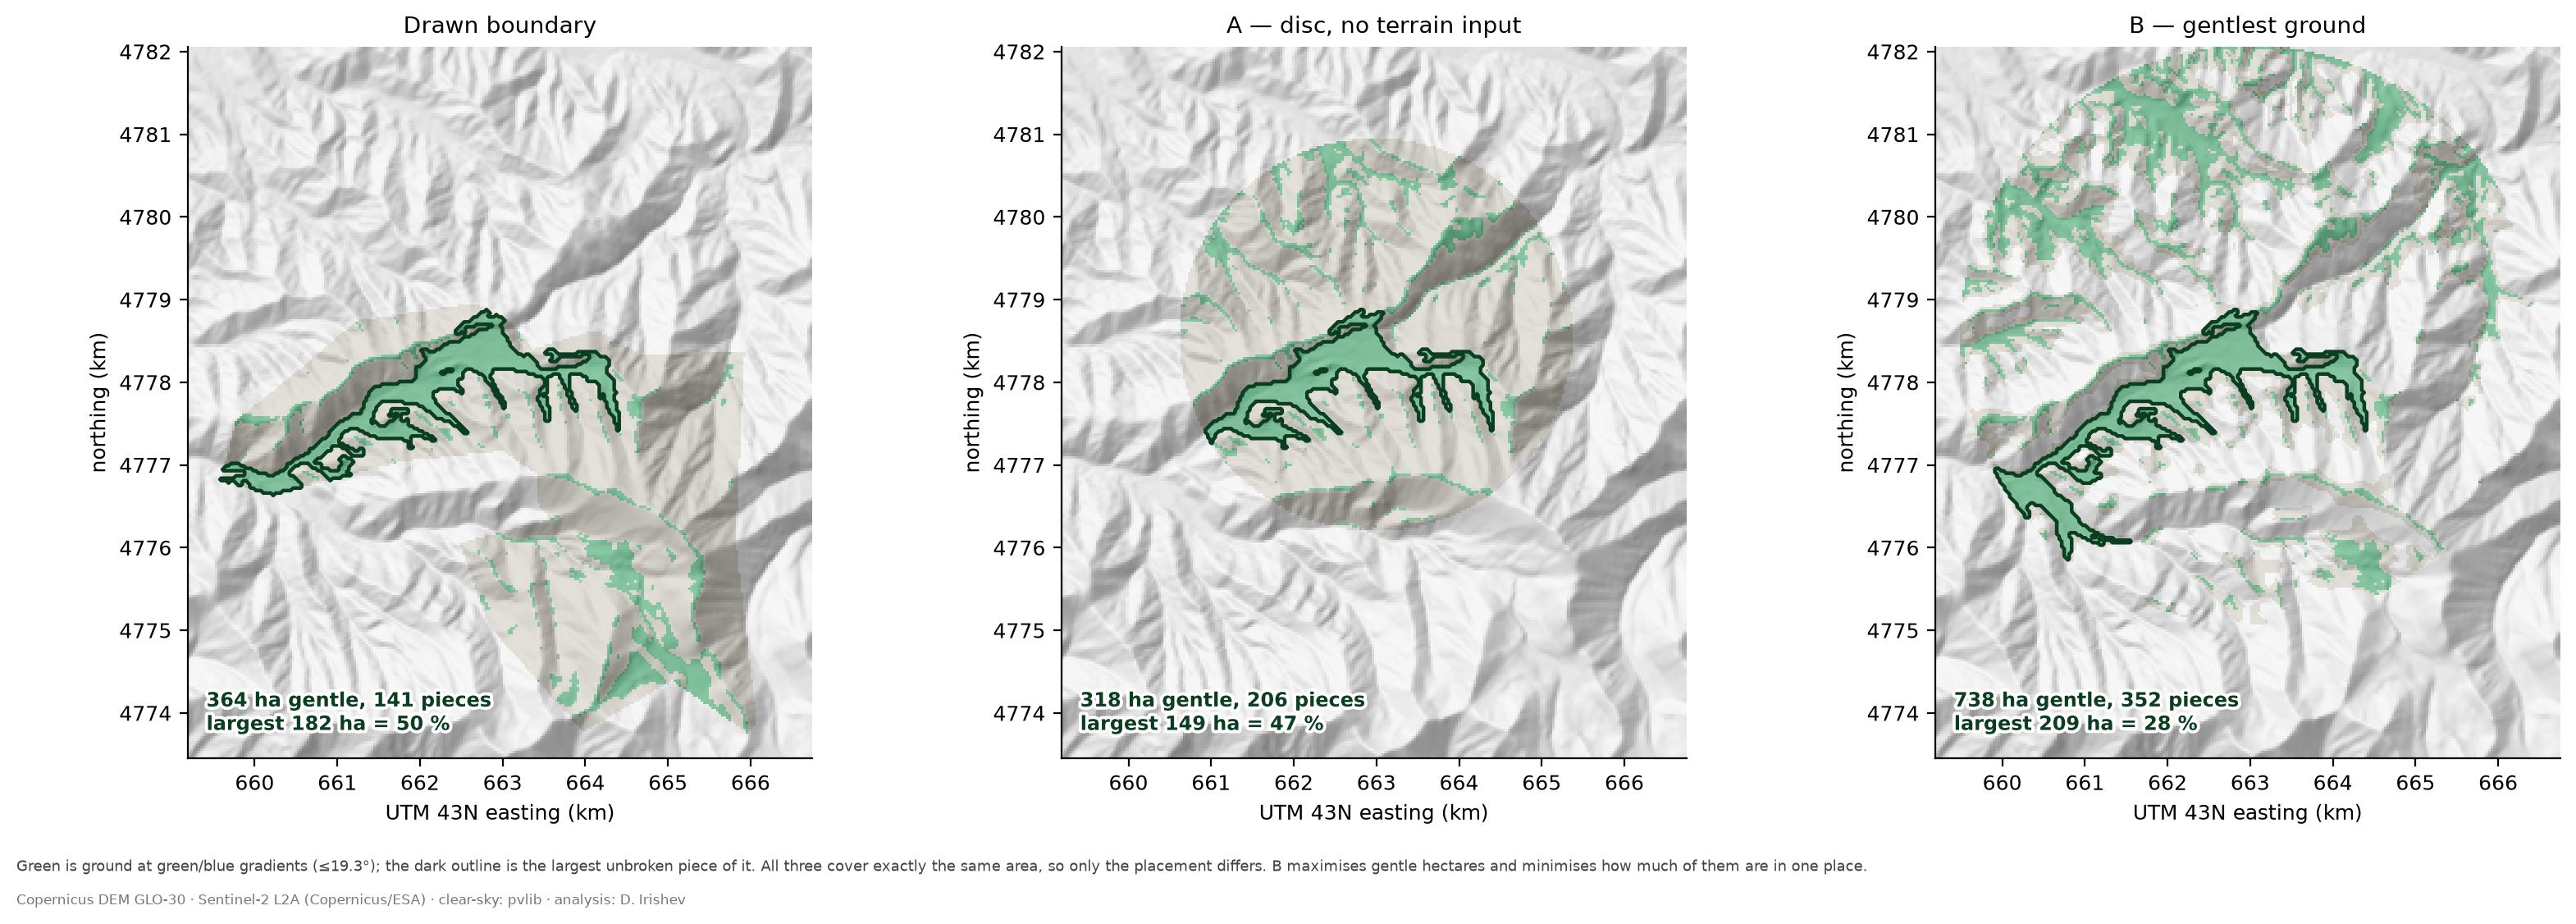

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/07_boundary_vs_reconstructions.png')

In [6]:
PL.figure_reconstructions(dem, slope, alts)

## 4. The published mix of runs, against the gradients that exist

Two published sources disagree, so both are carried and every table names which
one it used. The operator's own general plan gives a four-way difficulty split;
press reporting of the April 2026 statement gave a round number. The plan
attaches its own 70 % to **snowmaking**, which is the most economical
explanation of where the press figure came from.

In [7]:
print(f"general plan : {PROJECT_LIFTS} lifts, "
      f"{100 * PROJECT_GREEN_BLUE_SHARE:.1f} % green+blue, "
      f"{100 * PROJECT_SNOWMAKING_SHARE:.0f} % snowmaking")
print(f"press        : {PROJECT_LIFTS_PRESS} lifts, "
      f"about {100 * PROJECT_GREEN_BLUE_SHARE_PRESS:.0f} % green+blue")
print()
print(PL.published_parameters().to_string(index=False))

general plan : 16 lifts, 60.9 % green+blue, 70 % snowmaking
press        : 17 lifts, about 70 % green+blue

                                       parameter                                published                      source
                                    piste length                                    60 km          both sources agree
                                           lifts                                       16       general plan, sheet 3
                                           lifts                                       17 press, April 2026 statement
                               cableways by POMA                                       11      statement, 18 Nov 2026
                             runs green and blue          60.9 % (10.6 green + 50.3 blue)       general plan, sheet 3
                              runs red and black           39.1 % (22.7 red + 16.4 black)       general plan, sheet 3
                             runs green and blue                  

In [8]:
grad = PL.gradients(slope, alts)
print(grad.pivot(index="gradient_class", columns="area", values="area_ha")
          .reindex([c[0] for c in ST.GRADIENT_CLASSES]).to_string())

area                   A - disc of the same area at the plateau  B - gentlest ground of the same area within 3.5 km  Drawn boundary
gradient_class                                                                                                                     
Beginner                                                   48.4                                               106.6            59.5
Novice                                                    120.5                                               272.5           141.9
Low intermediate                                          149.4                                               358.7           162.7
Intermediate                                              104.6                                               224.2           106.2
Advanced intermediate                                     601.6                                               741.3           608.8
Expert                                                    751.0             

In [9]:
gb_ha = float(cmp_df.loc[cmp_df.footprint == "Drawn boundary", "green_blue_ha"].iloc[0])
feas = PL.feasibility(gb_ha)
print(feas[["green_blue_source", "assumed_mean_piste_width_m", "green_blue_piste_ha",
            "available_green_blue_ha", "share_of_available_consumed"]].to_string(index=False))

                        green_blue_source  assumed_mean_piste_width_m  green_blue_piste_ha  available_green_blue_ha  share_of_available_consumed
general plan (10.6 % green + 50.3 % blue)                        30.0                109.6                    364.1                        0.301
general plan (10.6 % green + 50.3 % blue)                        40.0                146.2                    364.1                        0.402
general plan (10.6 % green + 50.3 % blue)                        50.0                182.7                    364.1                        0.502
             press statement (about 70 %)                        30.0                126.0                    364.1                        0.346
             press statement (about 70 %)                        40.0                168.0                    364.1                        0.461
             press statement (about 70 %)                        50.0                210.0                    364.1               

**The easy-terrain budget closes with room** — 30–50 % of available gentle
ground on the plan's own mix, 35–58 % on the press figure.

An earlier draft of this project put the same arithmetic at up to **101 %** and
concluded that easy terrain was the binding constraint. That figure combined the
superseded footprint with the conflated 70 %, and it is **withdrawn**
(`METHODS.md` §31). What a 30 m DEM still cannot show is whether two gentle
benches can be joined by a lift. That is a survey question.

## 5. Sun inside the boundary

Energy and duration answer different questions, and for a December launch the
one that matters is *hours of direct sun on the ground people ski on*.

In [10]:
sun = PL.sun(mask, slope)
print(sun.to_string(index=False))

   month  days  median_sun_h  median_h_per_day  p10_sun_h  p90_sun_h  median_sun_h_green_blue  median_h_per_day_green_blue  median_total_kwh_m2  median_shaded_fraction
November    30         157.3              5.24        0.3      233.3                    204.0                         6.80                 53.9                   0.454
December    31         110.5              3.56        0.0      212.9                    168.0                         5.42                 29.6                   0.591
 January    31         138.6              4.47        0.0      228.2                    190.4                         6.14                 42.8                   0.514
February    28         188.5              6.73       58.1      243.3                    223.3                         7.98                 80.7                   0.353
   March    31         274.3              8.85      201.0      318.3                    300.8                         9.70                154.4                 

The important column is the last pair. **The median pixel sees 3.6 h of direct
sun a day in December and the bottom tenth sees none — but the green and blue
ground sees 5.4 h.** The plateau faces the city, which is north; the gentle
shelves that would carry beginner runs are not the north-facing part of it.

That inverts an earlier reading of this site, which took the whole footprint's
December median as the number a beginner area would live with.

## 6. Snow, and the snow record's own blind spot

A pixel needs four cloud- and shadow-free observations before it enters a monthly
map. Shaded ground fails that test more often, so in mid-winter the pixels that
survive are the sunniest and flattest — and the median then describes *that
ground*, not the site. The bias columns measure it instead of leaving it to a
caveat.

In [11]:
snow, ctx = PL.snow(poly, dem, slope)
print(snow.to_string(index=False))

   month  dates  qualifying_share  median_valid_obs  median_snow_frequency  dec_insolation_bias_kwh  slope_bias_deg
November     24             0.768                17                  0.884                     19.8            -2.4
December     16             0.519                 5                  1.000                     42.5            -4.0
 January     16             0.596                 9                  1.000                     35.0            -3.6
February     13             0.922                11                  1.000                      5.1            -0.6
   March     25             0.979                24                  1.000                      1.3            -0.2
   April     17             0.940                14                  0.875                      4.0            -0.4


March is sound: 97.9 % of the area qualifies on a median of 24 observations with
a bias near zero. **December is not**: barely half the area qualifies, on a
median of 5 observations, and those pixels are ~43 kWh/m² sunnier and 4° flatter
than the site. The December snow figure is real, but it is a figure about the
sunnier half of the boundary and is labelled as such everywhere it appears.

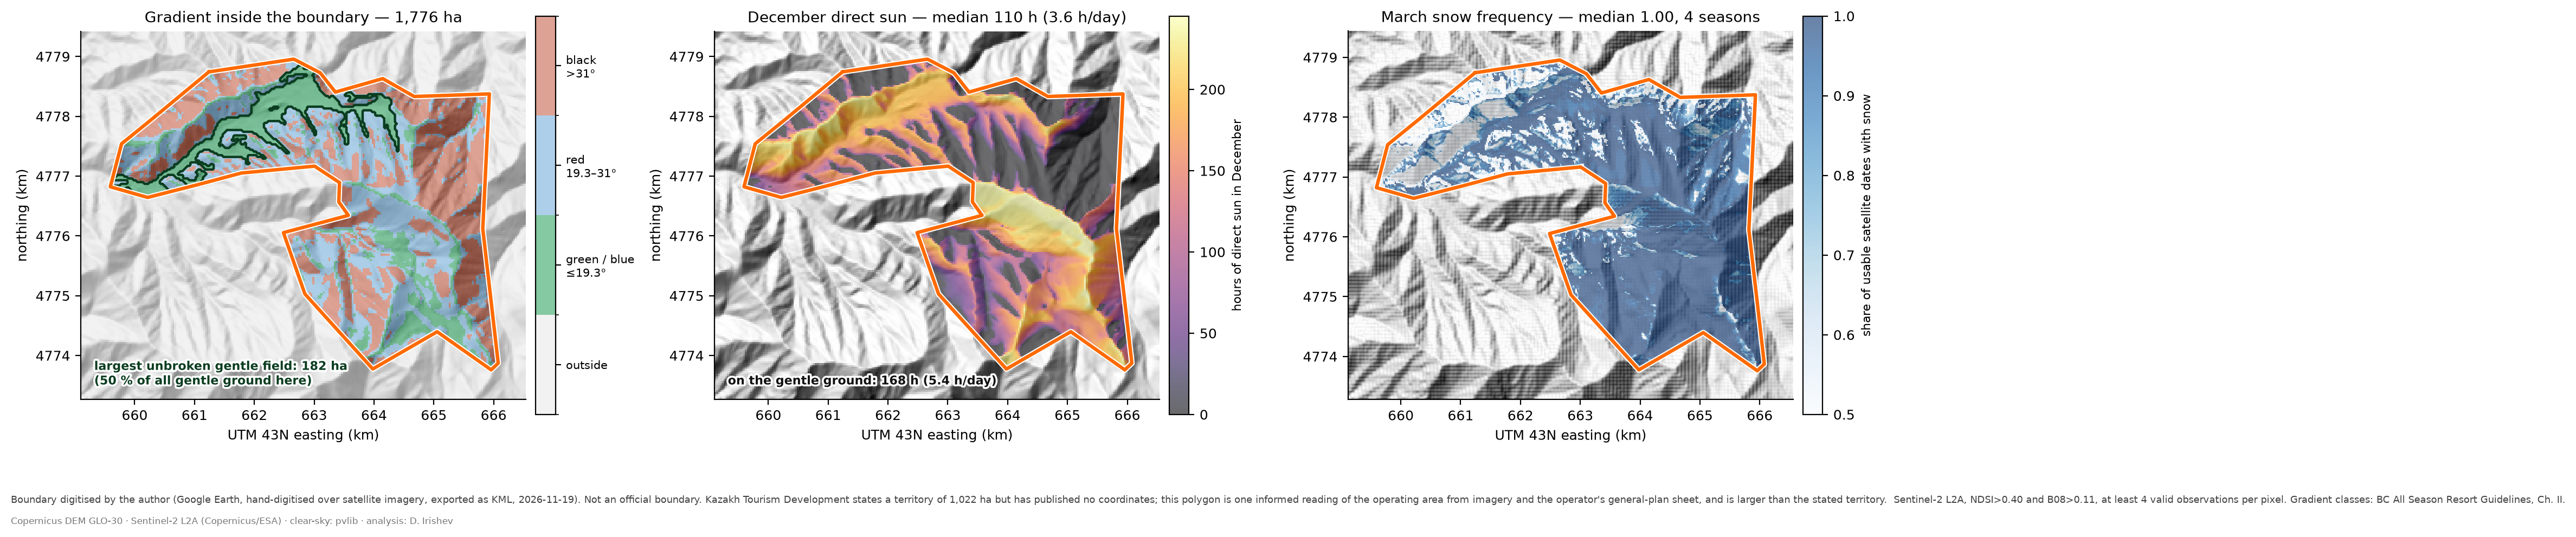

PosixPath('/Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png/06_operating_area.png')

In [12]:
PL.figure(poly, props, dem, slope, mask, ctx)

## 7. What this notebook supersedes

| earlier claim | where | status |
|---|---|---|
| 69 km² rectangle is the study area | nb 01–03 | superseded by the control-point extent |
| 1,022 ha reconstructed as footprints A and B | nb 05 §1 | kept as the adversarial reference only |
| green/blue runs need up to 101 % of available ground | nb 05 §2 | **withdrawn** — 30–50 % here |
| gentle ground exists but is not in one place | nb 05 §1 | **withdrawn** — half of it is one 182 ha field |
| placement moves December sun by 3.9× | nb 05 §3 | narrowed — gentle ground is the sunny ground |
| 17 lifts, about 70 % green and blue | nb 05 §0 | superseded by the general plan; both carried |

Notebook 04 (the 404 km² cluster) and notebook 05 §5–§6 (the three-area
comparison and the DEM propagation check) are **unaffected**: neither depends on
where this boundary is drawn.

## 8. Outputs

Everything on this page is written by one command:

```bash
KZ_AREA=superski python src/pipeline_operating_area.py
```

In [13]:
print(f"tables  -> {OUT_TAB}")
for p in sorted(OUT_TAB.glob("operating_area_*.csv")) + sorted(OUT_TAB.glob("published_*.csv")):
    print(f"   {p.name:46s} {p.stat().st_size/1024:6.1f} KB")
print(f"\nfigures -> {OUT_PNG}")
for p in sorted(OUT_PNG.glob("*.png")):
    print(f"   {p.name:46s} {p.stat().st_size/1e6:6.2f} MB")
print(f"\nboundary -> qgis/operating_area.geojson  ({int(summary['n_vertices'])} vertices)")

tables  -> /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/tables
   operating_area_gradient_classes.csv               1.6 KB
   operating_area_piste_feasibility.csv              0.6 KB
   operating_area_snow_by_month.csv                  0.3 KB
   operating_area_summary.csv                        0.7 KB
   operating_area_sun_by_month.csv                   0.5 KB
   operating_area_vs_reconstructions.csv             0.5 KB
   published_project_parameters.csv                  0.9 KB

figures -> /Users/diasirishev/Desktop/CodeBase/kok-zhailay/kok-zhailau-ski-terrain-analytics/outputs/superski/png
   06_operating_area.png                            1.19 MB
   07_boundary_vs_reconstructions.png               0.50 MB

boundary -> qgis/operating_area.geojson  (24 vertices)
